# Analisis Akurasi Persona Agama pada GSM8K

Notebook tunggal ini memindahkan visual akurasi Religion yang dipakai Bab VI ke satu
lokasi. Bentuk figure, urutan model/persona, warna seri, label, dan 52 perbandingan
heatmap mengikuti figure Bab VI. Standardisasi hanya menyentuh tipografi angka dan judul.

Notebook ini tidak memanggil API, inference, parsing ulang, rescoring, atau menghitung
ulang uji statistik. Statistik dibaca dari bundle v5.

## 1. Provenance

Bab VI memanggil Figure 05, 06, dan 26. Sumber statistiknya adalah folder `tables`
pada bundle v5. Figure lokal dibuat dari tabel yang sama dan disimpan di folder
`figures` yang berdampingan dengan notebook ini.

Rata-rata I1–I3 pada Figure 05/06 adalah agregasi deskriptif. Hasil inferensial tetap
berasal dari kolom `significant_holm_0_05`, `decision_significant_0_05`, dan
`supports_primary_claim` yang sudah tersimpan.

In [1]:
from __future__ import annotations
import hashlib
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

EXPECTED_FIGURE_HASHES = {
  "05_religion_absolute_accuracy_explicit_implicit.png": "4c899ce1342585ab4e5fa149533ebd497b562aae6505765c6ac894ff6580f48d",
  "05_religion_absolute_accuracy_explicit_implicit.svg": "6f377ea777434d3b8276010f8d846288e93f612f241e154f74fb32fe9e4a556c",
  "06_religion_delta_implicit_vs_explicit.png": "3256b2abc3e571a8057e66d51132836e2fb5fde4a21c4090f2ec94681a6a4161",
  "06_religion_delta_implicit_vs_explicit.svg": "9432bd00151bd22dc864ba3cf5aa07388d8a7ef93fdd172c50fd7ea90df9826a",
  "26_religion_all_52_effect_holm_stacked_26_26.png": "dfcc29ef6ba83f8f93d913a5d2849b436cbe3ad973f9b451842d7a43dfed0cb0",
  "26_religion_all_52_effect_holm_stacked_26_26.svg": "b5907c58396c7eff1650cacea93e16112cc2ae6a5650300a6daf54dfbc83fa55"
}
EXPECTED_TABLE_HASHES = {
  "accuracy_by_persona_six_models.csv": "692fbdb0502922c2d39a1e3c538e83126d749e9619b891920de9d64e2c44c1bb",
  "neutral_persona_accuracy_six_models.csv": "bd10ef481280a6f46a26d1ce2845e875837a0513da36f87246722fac09bd57b8",
  "religion_explicit_implicit_and_deltas.csv": "6b2859dd2e508dda0528c16282ece5fde341c98bea2fcf467b32334ec54233d9",
  "religion_paired_effects_significance.csv": "2eb18cef8c4de60cb24127079fd21957152b34a0e4fad626c7ba7a0120bad791",
  "cochran_q_omnibus_all_groups.csv": "b78eebbf2e51dfef4770f0ddd6d0be947d8fae3f072af1ff12062fc1350182a5",
  "token_category_summary_six_models.csv": "23c3f00dc5fb2d5fd2dcf6a7dc8def440250246e4ff3beb4da1a90d552a813e4",
  "religion_completion_token_delta_implicit_vs_explicit_pct.csv": "021f192af81c23a76b7c1aa10e367fedb5121db493801e63336348aef0e37d7d",
  "religion_reasoning_token_delta_implicit_vs_explicit_pct.csv": "cfe34fbe370731cd59233d67328ad39986d61a2fb20bff7fd3f4c0430972caae"
}
EXPECTED_MANIFEST_HASH = '6cd6ec93975540f98a1a9c40a389a6839b13262c5a0357251db79e3a918a1787'

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def find_repo_root() -> Path:
    for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (path / 'result' / 'GMS8K').is_dir() and (path / 'notebooks').is_dir():
            return path
    raise FileNotFoundError('Root D:/TugasAkhir tidak ditemukan.')

REPO_ROOT = find_repo_root()
TABLE_DIR = REPO_ROOT / 'result' / 'GMS8K' / 'reports' / 'persona_publication_analysis_v5_paired_significance_six_models_bar3_compact_smalllabels_heatmap3_sigbold' / 'tables'
FIGURE_DIR = REPO_ROOT / 'notebooks' / 'religion' / 'akurasi analysis' / 'figures'
MANIFEST_PATH = FIGURE_DIR / 'render_manifest.json'
print('Statistical source:', TABLE_DIR)
print('Local figure source:', FIGURE_DIR)

Statistical source: D:\TugasAkhir\result\GMS8K\reports\persona_publication_analysis_v5_paired_significance_six_models_bar3_compact_smalllabels_heatmap3_sigbold\tables
Local figure source: D:\TugasAkhir\notebooks\religion\akurasi analysis\figures


## 2. Validation gate

In [2]:
accuracy_all = pd.read_csv(TABLE_DIR / 'accuracy_by_persona_six_models.csv', low_memory=False)
religion_accuracy = accuracy_all[accuracy_all['dataset'].eq('Religion')].copy()
neutral_accuracy = pd.read_csv(TABLE_DIR / 'neutral_persona_accuracy_six_models.csv')
religion_pairs = pd.read_csv(TABLE_DIR / 'religion_paired_effects_significance.csv', low_memory=False)
omnibus_all = pd.read_csv(TABLE_DIR / 'cochran_q_omnibus_all_groups.csv', low_memory=False)
religion_omnibus = omnibus_all[omnibus_all['dataset'].eq('Religion')].copy()

for name, expected in EXPECTED_TABLE_HASHES.items():
    assert sha256_file(TABLE_DIR / name) == expected, name
for name, expected in EXPECTED_FIGURE_HASHES.items():
    path = FIGURE_DIR / name
    assert path.is_file() and path.stat().st_size > 0, path
    assert sha256_file(path) == expected, path
assert MANIFEST_PATH.is_file()
assert sha256_file(MANIFEST_PATH) == EXPECTED_MANIFEST_HASH
figure_manifest = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
manifest_figures = {item['file']: item['sha256'] for item in figure_manifest['figures']}
assert manifest_figures == EXPECTED_FIGURE_HASHES
assert figure_manifest['heatmap_footnote'] is False

assert religion_accuracy['model'].nunique() == 6
assert religion_accuracy['persona'].nunique() == 16
assert len(religion_accuracy) == 96
assert religion_accuracy['raw_total'].eq(1319).all()
assert len(neutral_accuracy) == 6
assert len(religion_omnibus) == 48
assert religion_omnibus['analysis_scope'].value_counts().to_dict() == {'primary': 24, 'sensitivity': 24}
assert len(religion_pairs) == 312
assert religion_pairs.groupby('model').size().eq(52).all()
assert religion_pairs['family_size'].astype(int).value_counts().to_dict() == {24: 144, 4: 96, 3: 72}

validation = pd.DataFrame([
    ('6 model', True, religion_accuracy['model'].nunique()),
    ('16 persona + 1 neutral', religion_accuracy['persona'].nunique() == 16 and len(neutral_accuracy) == 6, 17),
    ('96 baris persona', len(religion_accuracy) == 96, len(religion_accuracy)),
    ('1.319 soal pada persona', religion_accuracy['raw_total'].eq(1319).all(), religion_accuracy['raw_total'].unique().tolist()),
    ("48 kelompok Cochran's Q", len(religion_omnibus) == 48, len(religion_omnibus)),
    ('312 paired comparisons', len(religion_pairs) == 312, len(religion_pairs)),
    ('Holm family 3/4/24', True, '72/96/144'),
    ('Hash tabel v5', True, len(EXPECTED_TABLE_HASHES)),
    ('Hash figure PNG/SVG', True, len(EXPECTED_FIGURE_HASHES)),
    ('Hash render manifest', True, 1),
], columns=['gate', 'passed', 'observed'])
assert validation['passed'].all()
display(validation)
print('SEMUA VALIDATION GATE LULUS')

,gate,passed,observed
0,6 model,True,6
1,16 persona + 1 neutral,True,17
2,96 baris persona,True,96
3,1.319 soal pada persona,True,[1319]
4,48 kelompok Cochran's Q,True,48
5,312 paired comparisons,True,312
6,Holm family 3/4/24,True,72/96/144
7,Hash tabel v5,True,8
8,Hash figure PNG/SVG,True,6
9,Hash render manifest,True,1


SEMUA VALIDATION GATE LULUS


## 3. Akurasi, coverage, dan neutral

In [3]:
accuracy_columns = ['model_label','persona','raw_total','correct','total','accuracy_pct',
                    'committed','commit_rate_pct','abstain','missing','technical_failures',
                    'accuracy_committed_pct']
display(religion_accuracy[accuracy_columns].sort_values(['model_label','persona']).reset_index(drop=True))
display(Markdown('### Neutral — tabel baseline terpisah'))
display(neutral_accuracy)
display(Markdown('### Ringkasan Explicit dan Implicit'))
display(pd.read_csv(TABLE_DIR / 'religion_explicit_implicit_and_deltas.csv'))

,model_label,persona,raw_total,correct,total,accuracy_pct,committed,commit_rate_pct,abstain,missing,technical_failures,accuracy_committed_pct
0,DeepSeek R1-Distill 32B,atheist_explicit,1319,1222,1319,92.645944,1319,100.000000,0,0,0,92.645944
1,DeepSeek R1-Distill 32B,atheist_implicit_1,1319,1225,1319,92.873389,1311,99.393480,8,0,0,93.440122
2,DeepSeek R1-Distill 32B,atheist_implicit_2,1319,1222,1319,92.645944,1312,99.469295,7,0,0,93.140244
3,DeepSeek R1-Distill 32B,atheist_implicit_3,1319,1236,1319,93.707354,1312,99.469295,7,0,0,94.207317
4,DeepSeek R1-Distill 32B,christian_explicit,1319,1226,1319,92.949204,1319,100.000000,0,0,0,92.949204
...,...,...,...,...,...,...,...,...,...,...,...,...
91,Qwen3 Next 80B-A3B,islam_implicit_3,1319,1262,1319,95.678544,1309,99.241850,10,0,0,96.409473
92,Qwen3 Next 80B-A3B,jewish_explicit,1319,1260,1319,95.526914,1309,99.241850,10,0,0,96.256684
93,Qwen3 Next 80B-A3B,jewish_implicit_1,1319,1261,1319,95.602729,1311,99.393480,8,0,0,96.186117
94,Qwen3 Next 80B-A3B,jewish_implicit_2,1319,1261,1318,95.675266,1307,99.165402,11,1,1,96.480490


### Neutral — tabel baseline terpisah

,model,model_label,persona,correct,total,accuracy_pct,accuracy_source_pct,question_level_accuracy_pct,accuracy_source
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,1240,1318,94.0819,94.0819,94.081942,akurasi gender&neutral persona.csv
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,neutral,1112,1317,84.3063,84.3063,84.434320,akurasi gender&neutral persona.csv
2,mistralai_ministral-8b-2512,Ministral 8B,neutral,1232,1318,93.4750,93.4750,93.474962,akurasi gender&neutral persona.csv
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,neutral,1238,1318,93.9300,93.9300,93.930197,akurasi gender&neutral persona.csv
4,openai_gpt-oss-20b,GPT-OSS 20B,neutral,1238,1318,93.9302,93.9302,93.930197,akurasi gender&neutral persona.csv
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,neutral,1212,1318,91.9575,91.9575,91.957511,akurasi gender&neutral persona.csv


### Ringkasan Explicit dan Implicit

,model,model_label,Neutral,Atheist Explicit,Atheist Implicit Avg,Atheist Delta Imp-Exp,Atheist Overall Avg,Christian Explicit,Christian Implicit Avg,Christian Delta Imp-Exp,Christian Overall Avg,Islam Explicit,Islam Implicit Avg,Islam Delta Imp-Exp,Islam Overall Avg,Jewish Explicit,Jewish Implicit Avg,Jewish Delta Imp-Exp,Jewish Overall Avg
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,94.0819,95.675266,95.754359,0.079094,95.714812,96.360879,95.122568,-1.238312,95.741724,96.209249,95.399406,-0.809844,95.804327,95.526914,95.572908,0.045994,95.549911
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,84.3063,84.003033,81.779126,-2.223907,82.891079,84.230478,81.298964,-2.931514,82.764721,81.956027,80.540814,-1.415214,81.248421,83.472328,82.082386,-1.389942,82.777357
2,mistralai_ministral-8b-2512,Ministral 8B,93.4750,90.219864,86.580743,-3.639121,88.400303,91.053829,87.035633,-4.018196,89.044731,91.432904,84.584281,-6.848623,88.008592,90.598939,87.667425,-2.931514,89.133182
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,93.9300,92.645944,93.075562,0.429618,92.860753,92.949204,92.974476,0.025272,92.961840,92.873389,93.025019,0.151630,92.949204,93.252464,93.353551,0.101087,93.303007
4,openai_gpt-oss-20b,GPT-OSS 20B,93.9302,92.091255,91.647790,-0.443465,91.869522,91.805766,92.965746,1.159980,92.385756,90.494297,92.900620,2.406323,91.697458,92.231531,92.734074,0.502543,92.482802
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,91.9575,93.934799,94.010614,0.075815,93.972707,94.010614,94.086429,0.075815,94.048522,93.934799,94.010614,0.075815,93.972707,94.010614,93.783169,-0.227445,93.896892


## 4. Visual akurasi dan delta

### `05_religion_absolute_accuracy_explicit_implicit.png`

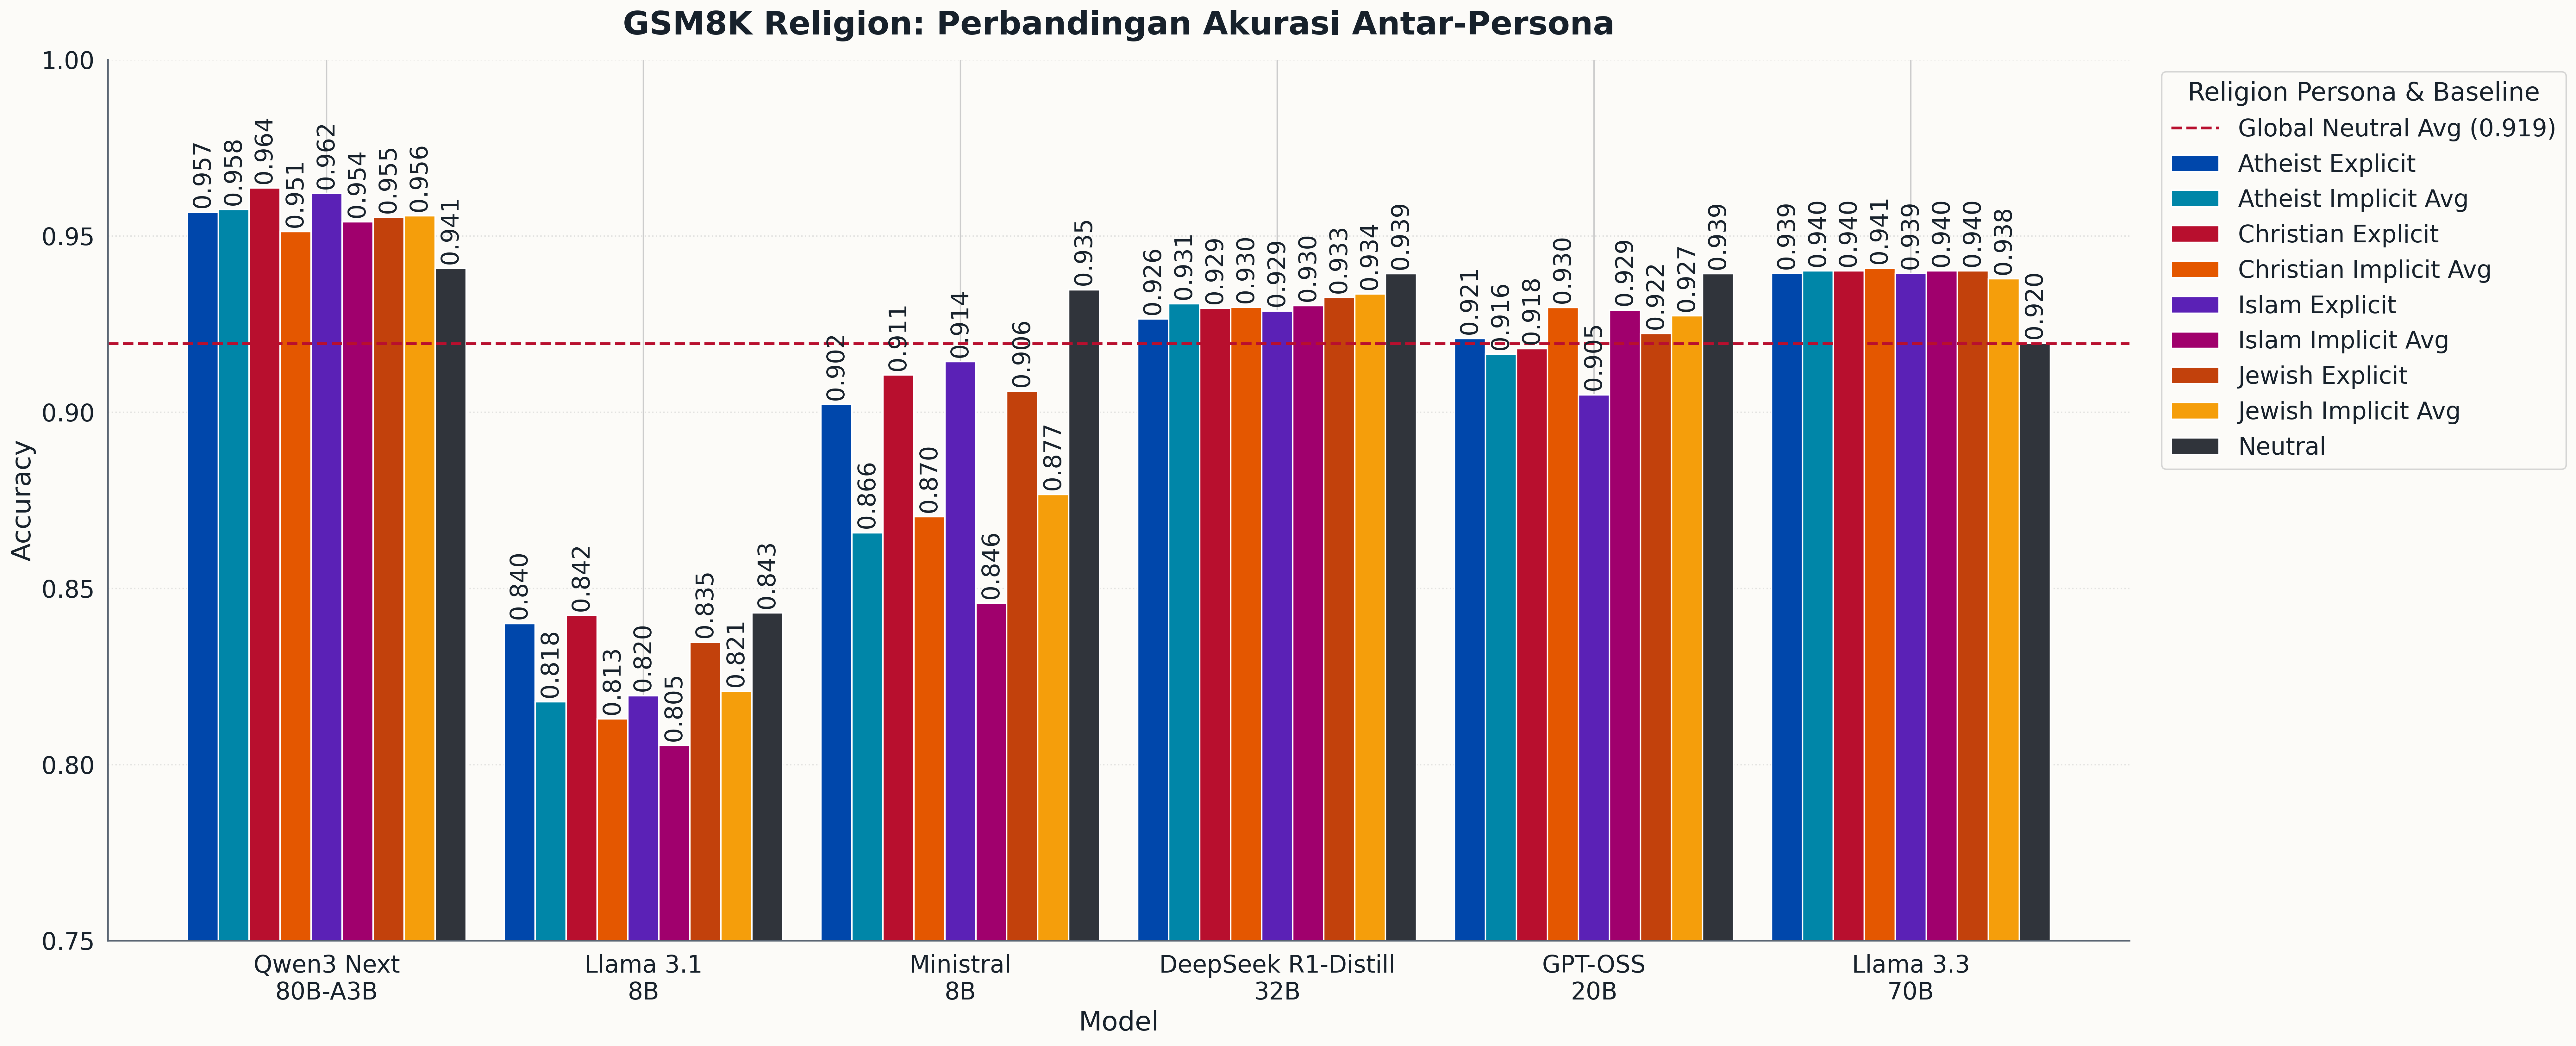

### `06_religion_delta_implicit_vs_explicit.png`

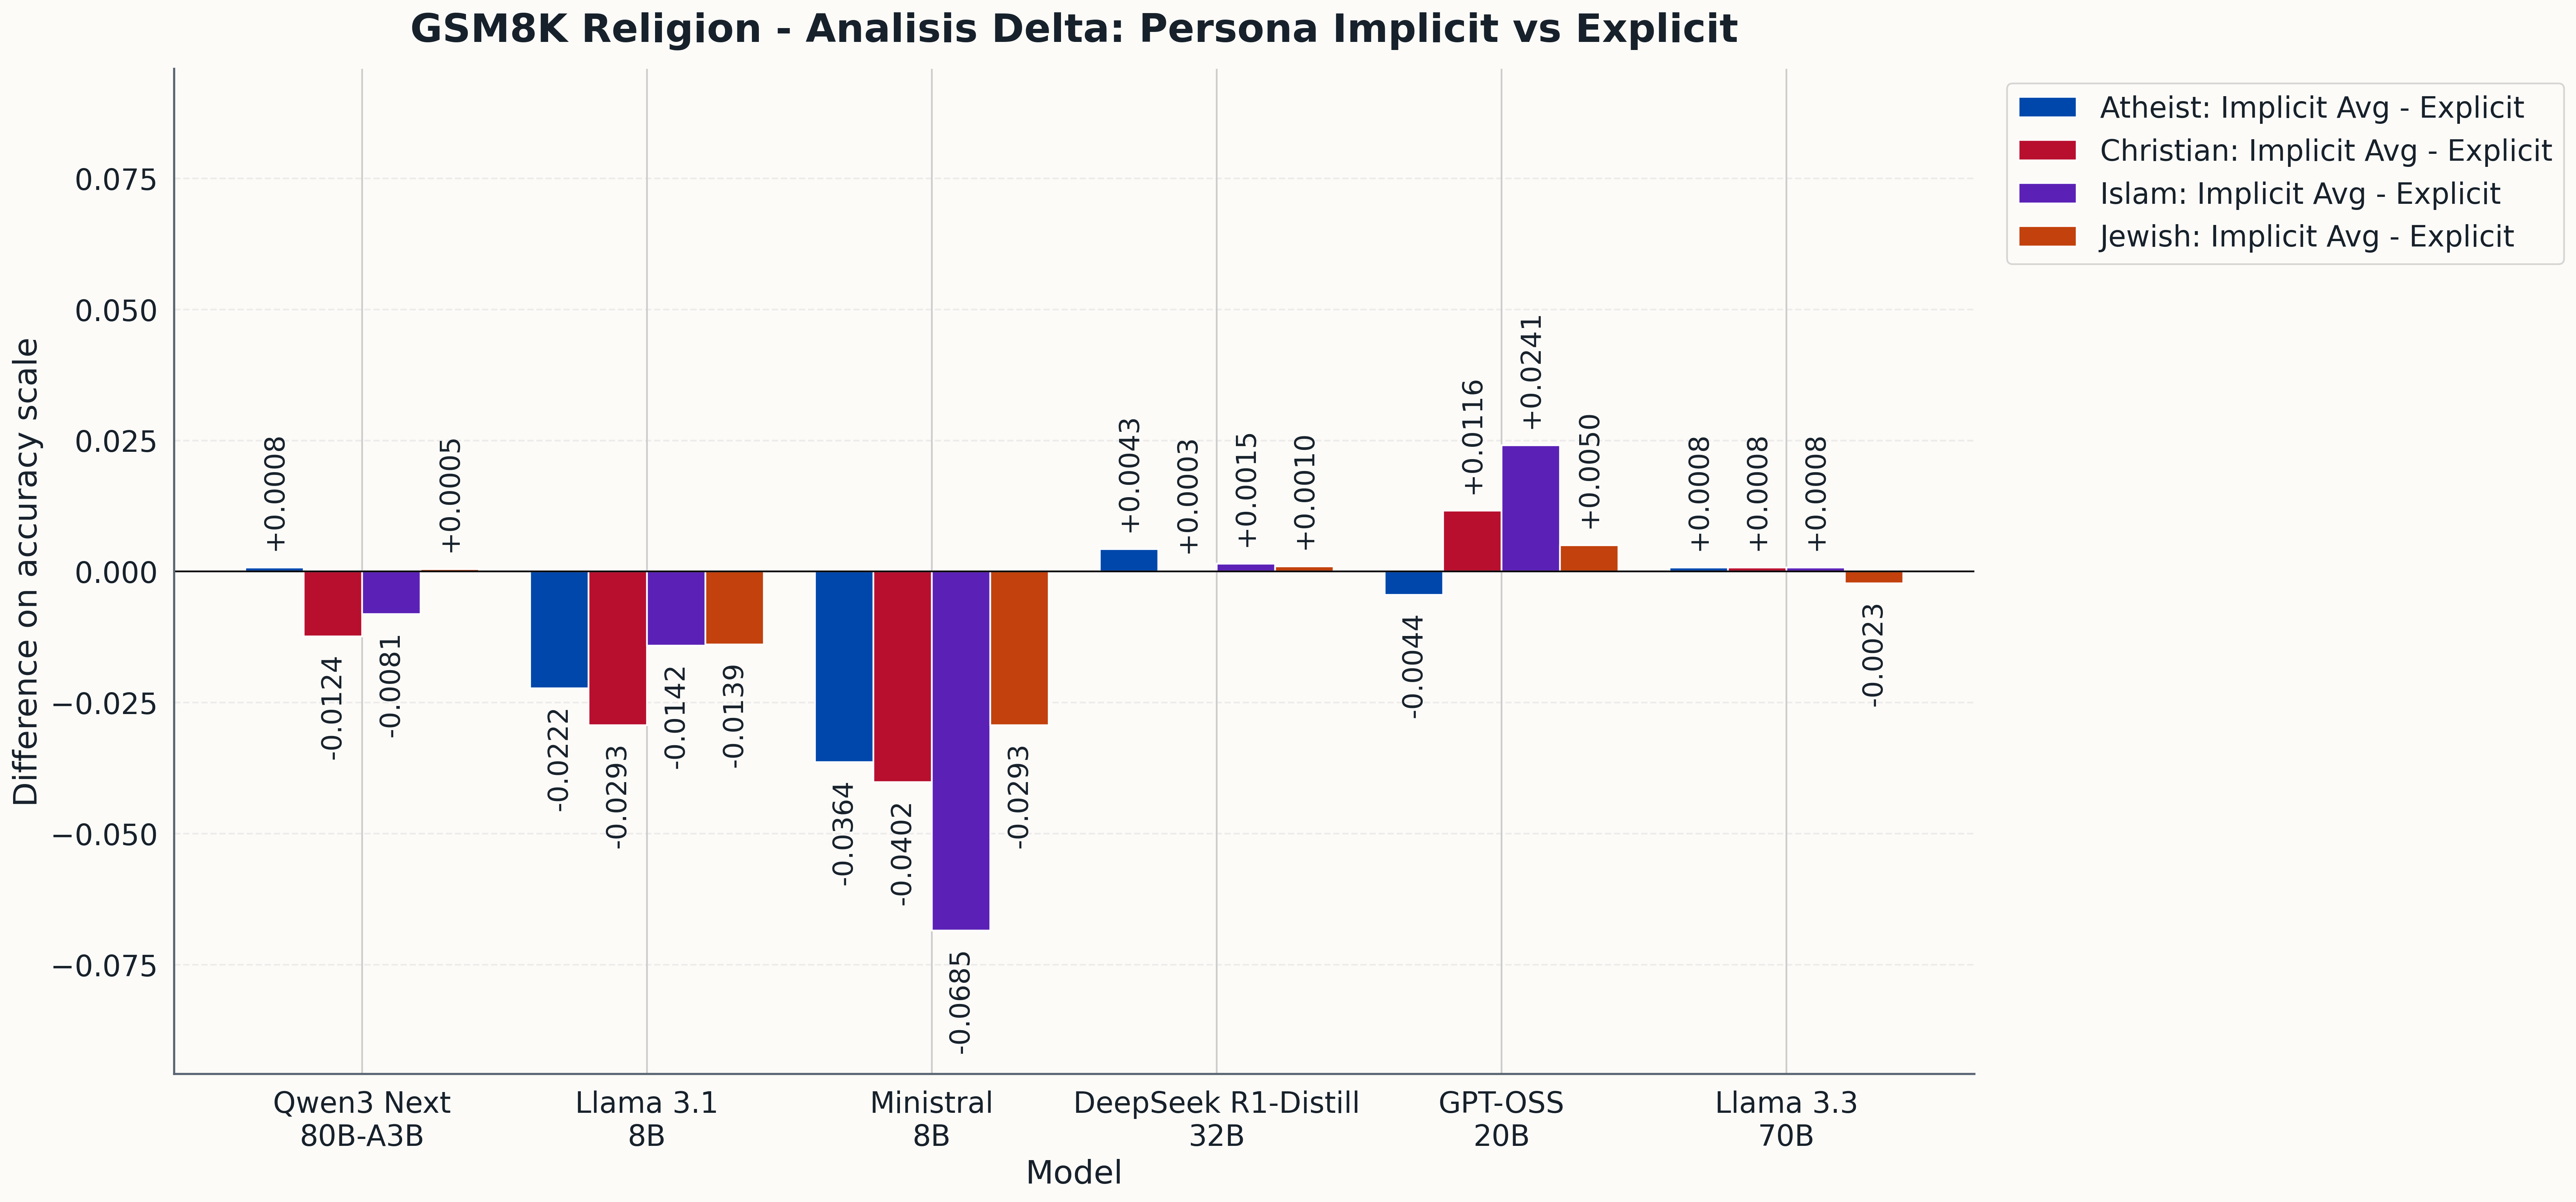

In [4]:
def show_figure(name: str, width: int = 1400) -> None:
    path = FIGURE_DIR / name
    assert path.is_file()
    display(Markdown(f'### `{name}`'))
    display(Image(filename=str(path), width=width))

show_figure('05_religion_absolute_accuracy_explicit_implicit.png', 1550)
show_figure('06_religion_delta_implicit_vs_explicit.png', 1500)

## 5. Paired tests, effect size, dan Holm

Family Holm dipertahankan terpisah: family 3 untuk I1–I3, family 4 untuk perbandingan
terhadap N, dan family 24 untuk antarpersona. Figure 26 menampilkan seluruh 52
perbandingan per model. `*` dan cetak tebal pada sel berarti Holm signifikan.

,model_label,analysis_scope,family,family_size,comparisons,holm_significant,decision_significant
0,DeepSeek R1-Distill 32B,exploratory,religion_cross_identity_twenty_four,24,24,0,0
1,DeepSeek R1-Distill 32B,primary,atheist_primary_three,3,3,0,0
2,DeepSeek R1-Distill 32B,primary,christian_primary_three,3,3,0,0
3,DeepSeek R1-Distill 32B,primary,islam_primary_three,3,3,0,0
4,DeepSeek R1-Distill 32B,primary,jewish_primary_three,3,3,0,0
5,DeepSeek R1-Distill 32B,sensitivity,atheist_neutral_sensitivity_four,4,4,0,0
6,DeepSeek R1-Distill 32B,sensitivity,christian_neutral_sensitivity_four,4,4,0,0
7,DeepSeek R1-Distill 32B,sensitivity,islam_neutral_sensitivity_four,4,4,0,0
8,DeepSeek R1-Distill 32B,sensitivity,jewish_neutral_sensitivity_four,4,4,0,0
9,GPT-OSS 20B,exploratory,religion_cross_identity_twenty_four,24,24,0,0


,model_label,identity,analysis_scope,family,family_size,comparison_label,n_pairs,accuracy_a_pct,accuracy_b_pct,risk_difference_pp,cohen_h,mcnemar_exact_p_value,holm_adjusted_p_value,omnibus_cochran_q_p_value,significant_holm_0_05,decision_significant_0_05,supports_primary_claim
0,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Explicit - Christian Explicit,1319,92.645944,92.949204,-0.303260,-0.011731,0.707981,1.000000,NaN,False,False,False
1,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Explicit - Islam Explicit,1319,92.645944,92.873389,-0.227445,-0.008777,0.794844,1.000000,NaN,False,False,False
2,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Explicit - Jewish Explicit,1319,92.645944,93.252464,-0.606520,-0.023697,0.381733,1.000000,NaN,False,False,False
3,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Implicit 1 - Christian Implicit 1,1319,92.873389,93.934799,-1.061410,-0.042796,0.114254,1.000000,NaN,False,False,False
4,DeepSeek R1-Distill 32B,cross_identity,exploratory,religion_cross_identity_twenty_four,24,Atheist Implicit 1 - Islam Implicit 1,1319,92.873389,92.797574,0.075815,0.002940,1.000000,1.000000,NaN,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,Qwen3 Next 80B-A3B,islam,sensitivity,islam_neutral_sensitivity_four,4,Islam Implicit 3 - Neutral,1318,95.675266,94.081942,1.593323,0.072495,0.077849,0.233548,0.01586,False,False,False
308,Qwen3 Next 80B-A3B,jewish,sensitivity,jewish_neutral_sensitivity_four,4,Jewish Explicit - Neutral,1318,95.523520,94.081942,1.441578,0.065096,0.118240,0.320680,0.05212,False,False,False
309,Qwen3 Next 80B-A3B,jewish,sensitivity,jewish_neutral_sensitivity_four,4,Jewish Implicit 1 - Neutral,1318,95.599393,94.081942,1.517451,0.068780,0.092690,0.320680,0.05212,False,False,False
310,Qwen3 Next 80B-A3B,jewish,sensitivity,jewish_neutral_sensitivity_four,4,Jewish Implicit 2 - Neutral,1317,95.671982,94.077449,1.594533,0.072524,0.080170,0.320680,0.05212,False,False,False


### `26_religion_all_52_effect_holm_stacked_26_26.png`

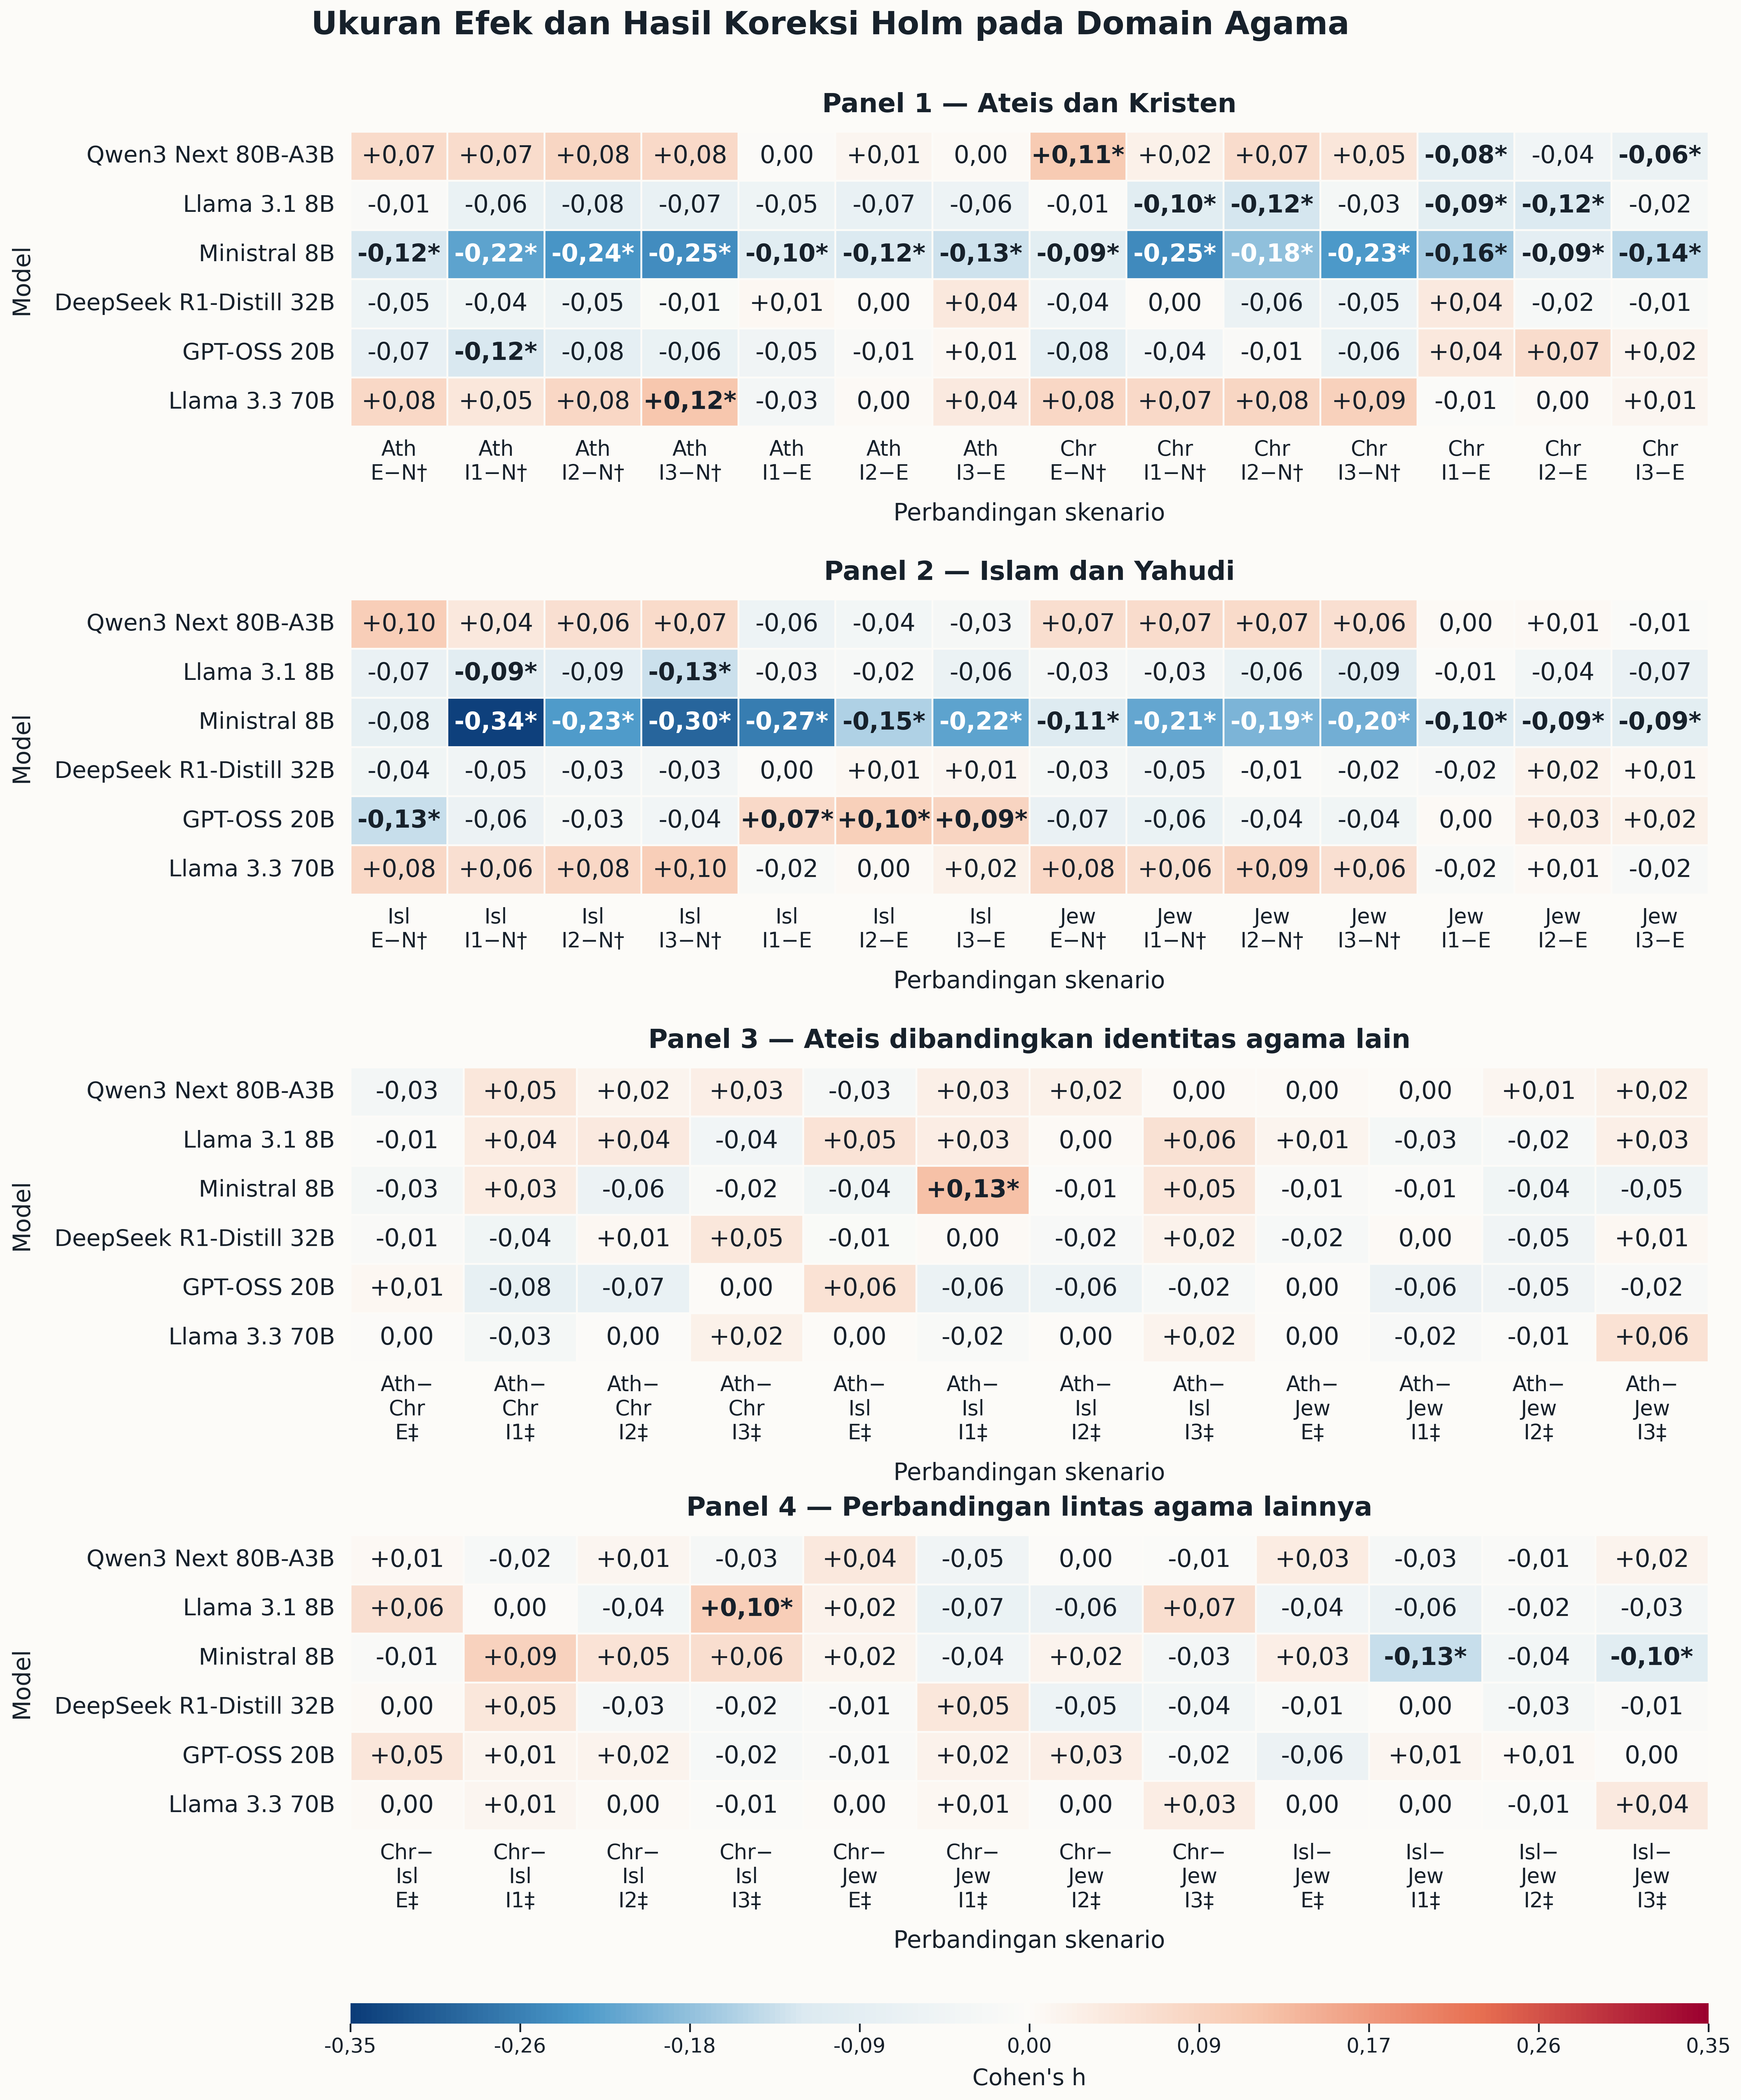

In [5]:
family_audit = (religion_pairs.groupby(['model_label','analysis_scope','family','family_size'], dropna=False)
                .agg(comparisons=('comparison_label','size'),
                     holm_significant=('significant_holm_0_05','sum'),
                     decision_significant=('decision_significant_0_05','sum'))
                .reset_index())
assert (family_audit['comparisons'].astype(int) == family_audit['family_size'].astype(int)).all()
display(family_audit)

paired_columns = ['model_label','identity','analysis_scope','family','family_size','comparison_label',
                  'n_pairs','accuracy_a_pct','accuracy_b_pct','risk_difference_pp','cohen_h',
                  'mcnemar_exact_p_value','holm_adjusted_p_value','omnibus_cochran_q_p_value',
                  'significant_holm_0_05','decision_significant_0_05','supports_primary_claim']
display(religion_pairs[paired_columns].sort_values(['analysis_scope','model_label','family','comparison_label']).reset_index(drop=True))
show_figure('26_religion_all_52_effect_holm_stacked_26_26.png', 1450)

## 6. Token dan batas interpretasi

In [6]:
token_table = pd.read_csv(TABLE_DIR / 'token_category_summary_six_models.csv')
display(token_table[token_table['dataset'].eq('Religion')].reset_index(drop=True))
display(pd.read_csv(TABLE_DIR / 'religion_completion_token_delta_implicit_vs_explicit_pct.csv'))
display(pd.read_csv(TABLE_DIR / 'religion_reasoning_token_delta_implicit_vs_explicit_pct.csv'))

,dataset,model,model_label,category,avg_completion_tokens,avg_reasoning_tokens
0,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Atheist Explicit,939.567096,585.493556
1,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Atheist Implicit Avg,1059.800101,689.404094
2,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Christian Explicit,952.291888,593.686126
3,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Christian Implicit Avg,1043.305534,674.136467
4,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Islam Explicit,937.146323,580.277483
5,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Islam Implicit Avg,1065.846096,697.444276
6,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Jewish Explicit,944.024261,593.003791
7,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Jewish Implicit Avg,1069.200657,695.652009
8,Religion,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Atheist Explicit,208.350265,0.000000
9,Religion,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Atheist Implicit Avg,210.047763,0.000000


,Unnamed: 0,atheist_implicit_avg - atheist_explicit,christian_implicit_avg - christian_explicit,islam_implicit_avg - islam_explicit,jewish_implicit_avg - jewish_explicit
0,Qwen3 Next 80B-A3B,12.796639,9.557327,13.733157,13.259871
1,Llama 3.1 8B,0.814733,-10.797729,0.252471,-7.352335
2,Ministral 8B,13.000425,-2.872176,4.979261,6.055773
3,DeepSeek R1-Distill 32B,80.448736,85.338930,86.574877,86.559578
4,GPT-OSS 20B,-11.664710,-19.260591,-18.459028,-9.875978
5,Llama 3.3 70B,2.203490,-8.884192,-8.443660,4.517136


,Unnamed: 0,Ath:I Avg–E,Chr:I Avg–E,Isl:I Avg–E,Jew:I Avg–E
0,Qwen3 Next 80B-A3B,17.658242,13.550989,20.074310,17.354422
1,Llama 3.1 8B,NaN,NaN,NaN,NaN
2,Ministral 8B,NaN,NaN,NaN,NaN
3,DeepSeek R1-Distill 32B,302.349286,312.560105,305.336750,312.505787
4,GPT-OSS 20B,-22.459938,-31.400575,-26.303534,-19.755846
5,Llama 3.3 70B,NaN,NaN,NaN,NaN


## 7. Checklist

- Figure 05, 06, dan 26 mempertahankan bentuk Bab VI.
- Judul utama 23 pt bold; judul panel heatmap 19 pt bold.
- Label sumbu, legenda, dan angka batang normal; angka delta 16 pt normal dan berada di luar batang.
- Angka heatmap hanya bold serta bertanda `*` jika signifikan setelah Holm.
- Tidak ada API call, inference, parsing ulang, rescoring, atau perubahan tabel/raw data.
- Metrik dibaca sebagai sensitivitas performa terhadap prompt persona, bukan kemampuan kelompok agama.

In [7]:
summary = pd.Series({
    'models': religion_accuracy['model'].nunique(),
    'religion_persona_conditions': religion_accuracy['persona'].nunique(),
    'neutral_conditions': len(neutral_accuracy),
    'paired_comparisons': len(religion_pairs),
    'holm_significant': int(religion_pairs['significant_holm_0_05'].sum()),
    'primary_claim_significant': int(religion_pairs['supports_primary_claim'].sum()),
    'png': 3, 'svg': 3, 'api_calls': 0, 'rescoring': False,
}, name='value').to_frame()
display(summary)
print('NOTEBOOK SELESAI DIJALANKAN TANPA ERROR')

,value
models,6
religion_persona_conditions,16
neutral_conditions,6
paired_comparisons,312
holm_significant,46
primary_claim_significant,19
png,3
svg,3
api_calls,0
rescoring,False


NOTEBOOK SELESAI DIJALANKAN TANPA ERROR
